# plottino examples

plottino makes matplotlib/seaborn figures at the size they will be printed, styles them for a
journal or a LaTeX document, and **checks that they are legible**. This notebook shows:

1. A figure for an Overleaf document, sized as `0.5\textwidth`
2. Checking a figure, and boxing its problems
3. The same figure, fixed
4. Journal presets with seaborn: panel letters, emphasis
5. The same figure at different printed widths
6. Checking a colour palette
7. Saving

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import plottino as pt

rng = np.random.default_rng(0)
years = np.arange(2000, 2021)
df = pd.DataFrame({
    'year': np.tile(years, 3),
    'value_eur': np.concatenate([np.cumsum(rng.normal(1, 1, len(years))) + k * 3 for k in range(3)]),
    'group': np.repeat(['control', 'treated early', 'treated late'], len(years)),
})

## 1. A figure for an Overleaf document

`pt.use_latex()` assumes the Overleaf default (`article`, 10pt, `\textwidth` = 345pt). For your own
document, print `\the\textwidth` in it and pass the number: `pt.use_latex(textwidth=418.25)`. Other
options: `pt.use_latex('a4-1in', fontsize=11)`, or `columnwidth=` for two-column documents.

`pt.figure(r'0.5\textwidth')` then makes the figure exactly that wide, with text at the document's
`\footnotesize`. Include it with `\includegraphics[width=0.5\textwidth]{...}`: nothing gets
rescaled, so the text prints at the size set here.

In [2]:
j = pt.use_latex()
print(j.name)
print('figure text:', j.font_size, 'pt; smallest allowed:', j.min_font, 'pt')
print('0.5\\textwidth =', round(j.width(r'0.5\textwidth'), 2), 'in')

LaTeX (345pt text, 10pt font)
figure text: 8.0 pt; smallest allowed: 6.0 pt
0.5\textwidth = 2.39 in


## 2. Check a figure

A typical first draft: red/green lines, legend on the data, a tiny annotation, a column name as
axis label.

plottino check: LaTeX (345pt text, 10pt font), figure 2.39 x 1.79 in
  x error   font_size        1 text(s) print at 4 pt, below the LaTeX (345pt text, 10pt font) minimum 6 pt: e.g. annotation "policy change" (axes 0)
  ! warning text_over_data   annotation "policy change" (axes 0) overlaps a line in axes 0
  ! warning legend_over_data the legend covers data in axes 0: move it (loc=, bbox_to_anchor=) or label the lines directly
  ! warning colors           #d62728 and #2ca02c look alike with deuteranopia (dE 3.9 < 6): change one, or add markers, line styles or direct labels
  i info    labels           y label "value_eur" of axes 0 looks like a variable name; write it for the reader, with units
  1 error, 3 warnings, 1 info

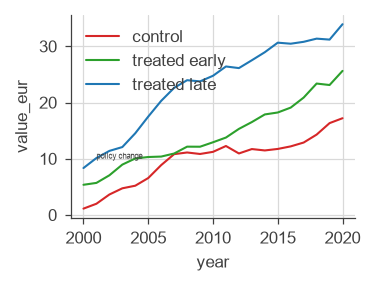

In [3]:
fig, ax = pt.figure(r'0.5\textwidth', aspect=0.75)
sns.lineplot(data=df, x='year', y='value_eur', hue='group',
             palette=['#d62728', '#2ca02c', '#1f77b4'], ax=ax)
ax.legend(loc='upper left')
ax.text(2001, 10, 'policy change', fontsize=4)

report = pt.check(fig)
report

`report.highlight()` boxes and numbers the problems on the figure (the numbers match the
report); `pt.clear_highlights(fig)` removes them. `pt.save` writes this view to
`<name>.check.png` automatically when there are errors or warnings.

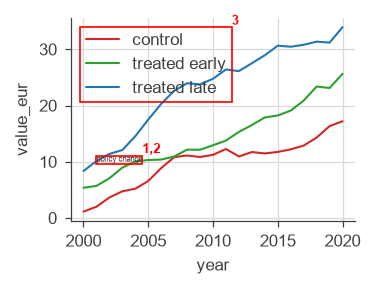

In [4]:
report.highlight()
fig

In [5]:
pt.clear_highlights(fig)
print('errors:', len(report.errors), '| warnings:', len(report.warnings), '| ok:', report.ok)

errors: 1 | warnings: 3 | ok: False


## 3. Fixed

Colour-blind-safe default palette (Okabe-Ito), lines labelled directly instead of a legend
(`pt.label_lines`), readable annotation, axis labels written for the reader.

plottino check: LaTeX (345pt text, 10pt font), figure 2.39 x 1.79 in
  no issues found

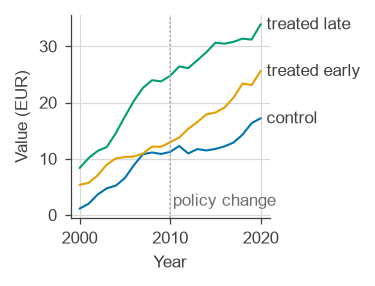

In [6]:
fig, ax = pt.figure(r'0.5\textwidth', aspect=0.75)
sns.lineplot(data=df, x='year', y='value_eur', hue='group', legend=False, ax=ax)
for line, name in zip(ax.lines, ['control', 'treated early', 'treated late']):
    line.set_label(name)
pt.label_lines(ax)
ax.axvline(2010, color=pt.GREY, lw=0.8, ls=':')
ax.text(2010.3, 1, 'policy change', color='#6e6e6e', va='bottom')
ax.set(xlabel='Year', ylabel='Value (EUR)', xticks=[2000, 2010, 2020])
pt.check(fig)

## 4. Journal presets with seaborn

`pt.use('science')` (or `'nature'`, `'pnas'`, `'cell'`) sets fonts, sizes and line widths and the
seaborn theme. Widths are the journal's columns: `pt.figure('double')`. `pt.panel_labels` adds
the panel letters in the journal's style; `pt.emphasize` greys out everything except the
series that carry the message.

plottino check: Science, figure 4.76 x 1.81 in
  i info    journal_rules    axis labels without units: 'Score', 'Threshold', 'Recall'; Science asks for "Quantity (unit)" (ignore for dimensionless quantities)
  1 info

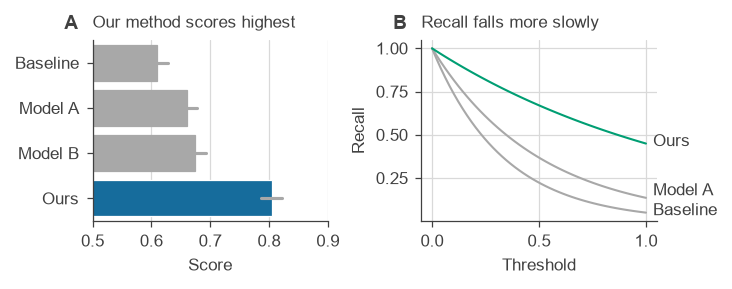

In [7]:
pt.use('science')
tips = pd.DataFrame({
    'method': np.repeat(['Baseline', 'Model A', 'Model B', 'Ours'], 30),
    'score': np.concatenate([rng.normal(m, 0.05, 30) for m in (0.60, 0.66, 0.68, 0.81)]),
})
fig, (a, b) = pt.figure('double', aspect=0.38, ncols=2)

sns.barplot(data=tips, x='score', y='method', ax=a, errorbar=('ci', 95))
for bar, name in zip(a.patches, tips.method.unique()):
    bar.set_label(name)
pt.emphasize(a, keep='Ours')
a.set(xlabel='Score', ylabel='', xlim=(0.5, 0.9), title='Our method scores highest')

x = np.linspace(0, 1, 50)
for rate, name in [(3, 'Baseline'), (2, 'Model A'), (0.8, 'Ours')]:
    b.plot(x, np.exp(-rate * x), label=name)
pt.emphasize(b, keep='Ours')
pt.label_lines(b)
b.set(xlabel='Threshold', ylabel='Recall', title='Recall falls more slowly')

pt.panel_labels([a, b])
pt.check(fig)

## 5. The same figure at different printed widths

A figure made at one size can be checked at the size it will be used: fonts and lines are
scaled. Here a figure designed for a full column is checked as if included at a third of the
text width: its text shrinks below the minimum.

plottino check: LaTeX (345pt text, 10pt font), figure 4.77 x 1.67 in
  no issues found

plottino check: LaTeX (345pt text, 10pt font), figure 4.77 x 1.67 in, printed at 1.58 in wide
  x error   font_size        10 text(s) print at 2.6 pt, below the LaTeX (345pt text, 10pt font) minimum 6 pt: e.g. x tick label "2000" (axes 0); x tick label "2005" (axes 0); x tick label "2010" (axes 0) (+7 more)
  ! warning size             width 4.77 in will be scaled to 1.58 in (0.33\textwidth), by 33%; fonts and lines are checked at that scale
  ! warning line_width       axis lines print at 0.2 pt, thinner than the LaTeX (345pt text, 10pt font) minimum 0.3 pt (axes 0)
  ! warning line_width       ticks print at 0.2 pt, thinner than the LaTeX (345pt text, 10pt font) minimum 0.3 pt (axes 0)
  i info    line_width       grid lines print at 0.2 pt, thinner than the LaTeX (345pt text, 10pt font) minimum 0.3 pt (axes 0)
  1 error, 3 warnings, 1 info


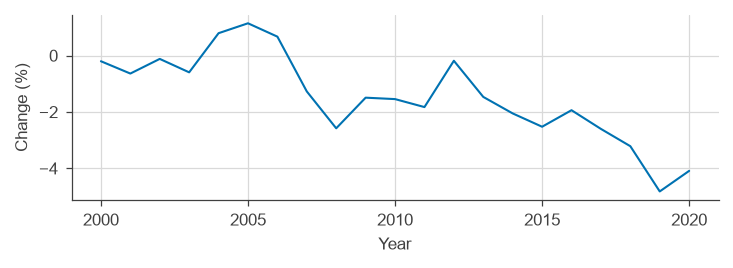

In [8]:
pt.use_latex()
fig, ax = pt.figure(r'\textwidth', aspect=0.35)
ax.plot(years, np.cumsum(rng.normal(size=len(years))))
ax.set(xlabel='Year', ylabel='Change (%)', xticks=[2000, 2005, 2010, 2015, 2020])

print(pt.check(fig))                          # as designed
print()
print(pt.check(fig, width=r'0.33\textwidth'))  # if included at a third of the width

## 6. Checking a colour palette

`pt.colors.check_palette` lists colour pairs that are hard to tell apart, with normal vision or
simulated protanopia, deuteranopia and tritanopia (OKLab distance x 100).

In [9]:
from matplotlib.colors import to_hex

tab10 = [to_hex(c) for c in plt.get_cmap('tab10').colors[:6]]   # matplotlib's default colours
for c1, c2, vision, d in pt.colors.check_palette(tab10, cvd_min=6):
    print(f'{c1} vs {c2}: alike with {vision} (dE {d:.1f})')
print('Okabe-Ito problems:', pt.colors.check_palette(pt.OKABE_ITO[:7], cvd_min=6))

#1f77b4 vs #9467bd: alike with protanopia (dE 1.7)
#ff7f0e vs #2ca02c: alike with protanopia (dE 0.7)
#2ca02c vs #d62728: alike with deuteranopia (dE 3.9)
#d62728 vs #8c564b: alike with protanopia (dE 4.6)
Okabe-Ito problems: []


## 7. Saving

`pt.save` checks the figure, prints the report if there is anything to report, and writes the
files at their exact size with embedded (editable) fonts. With a LaTeX width it prints the
matching `\includegraphics` line. `strict=True` refuses to save a figure with errors, useful in a
script that builds all the paper figures.

In [10]:
from pathlib import Path
out = Path('out'); out.mkdir(exist_ok=True)

fig, ax = pt.figure(r'0.5\textwidth', aspect=0.75)
ax.plot(years, np.cumsum(rng.normal(size=len(years))))
ax.set(xlabel='Year', ylabel='Change (%)')
pt.save(fig, out / 'example')          # example.pdf + example.png
plt.close(fig)

fig, ax = pt.figure(r'0.5\textwidth')
ax.plot([0, 1], [0, 1])
ax.set_xlabel('far too small', fontsize=3)
try:
    pt.save(fig, out / 'bad.pdf', strict=True, quiet=True)
except pt.FigureCheckError as e:
    print('not saved:', str(e).splitlines()[2])
plt.close(fig)

  LaTeX: \includegraphics[width=0.5\textwidth]{example}
not saved:   x error   font_size        1 text(s) print at 3 pt, below the LaTeX (345pt text, 10pt font) minimum 6 pt: e.g. x label "far too small" (axes 0)


### Exceptions

A label that sits on a bar on purpose: `pt.ignore(text, 'text_over_data')`. Skip a check for one
call: `pt.check(fig, skip=['font_family'])`. In a test or CI: `pt.check(fig).raise_for_errors()`.